# PRACTICUM DE ÎNVĂȚARE AUTOMATĂ: CODUL ȘI ALGORITMUL KNN
**Teme:** Preprocesarea datelor, Codificare categorială, Normalizare, Algoritmul K cei mai apropiați vecini (KNN), Ajustarea hiperparametrilor, Valori metrice ale distanței, Intel® Extension for Scikit-learn și Combaterea supraantrenării (Overfitting).

### Pregătirea datelor (setup comun)
Încărcăm setul Orange Telecom Churn și pregătim variabilele folosite în exerciții.

In [1]:
import os, time, timeit, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

RANDOM_STATE = 42
DATA_DIR = 'data' if os.path.isdir('data') else '.'
df_raw = pd.read_csv(os.path.join(DATA_DIR, 'Orange_Telecom_Churn_Data.csv'))
print("Dimensiunea setului de date:", df_raw.shape)

# Pregătirea de bază (ca în notebook-ul de referință):
# eliminăm state, area_code, phone_number și codificăm binar intl_plan / voice_mail_plan
df = df_raw.drop(columns=['state', 'area_code', 'phone_number']).copy()
df['intl_plan'] = (df['intl_plan'] == 'yes').astype(int)
df['voice_mail_plan'] = (df['voice_mail_plan'] == 'yes').astype(int)

X = df.drop(columns='churned')
y = df['churned'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

scaler = MinMaxScaler().fit(X_train)          # scalerul se ajustează DOAR pe train
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)
print("Train:", X_train_s.shape, " Test:", X_test_s.shape)
print("Proporția clientului care a renunțat (churn):", round(y.mean(), 3))

Dimensiunea setului de date: (5000, 21)
Train: (3500, 17)  Test: (1500, 17)
Proporția clientului care a renunțat (churn): 0.141


### Exercițiul 1: Ingineria caracteristicilor și eliminarea coloanelor irelevante
În setul de date Orange Telecom Churn, coloanele `state`, `area_code` și `phone_number` au fost eliminate în notebook. Scrieți un bloc de cod în Pandas care analizează cardinalitatea unică a fiecărei coloane categoriale rămase și eliminate. Explicați din punct de vedere matematic de ce aplicarea `OneHotEncoder` sau `LabelBinarizer` pe o coloană cu sute de valori unice (de exemplu, `phone_number`) va distruge eficiența spațială și va genera un risc ridicat de supraantrenare (overfitting) pentru algoritmul KNN.

In [2]:
# Cardinalitatea coloanelor categoriale (rămase + eliminate)
cat_cols = [c for c in df_raw.columns
            if (not pd.api.types.is_numeric_dtype(df_raw[c])) or c == 'area_code']
n = len(df_raw)

rows = []
for c in cat_cols:
    k = df_raw[c].nunique()
    rows.append({'coloana': c,
                 'status': 'eliminată' if c in ['state', 'area_code', 'phone_number'] else 'păstrată (binar)',
                 'valori_unice': k,
                 'raport_unice/rânduri': round(k / n, 4),
                 'coloane_după_OHE': k,
                 'memorie_OHE_dens (MB)': round(n * k * 8 / 1e6, 2)})
card = pd.DataFrame(rows).set_index('coloana')
display(card)

print("\nCardinalitatea tuturor coloanelor:")
print(df_raw.nunique().sort_values(ascending=False).head(8))

# --- Demonstrație: OneHotEncoder pe phone_number ---
from sklearn.preprocessing import OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
import scipy.sparse as sp

idx_tr, idx_te = X_train.index, X_test.index
ohe = OneHotEncoder(handle_unknown='ignore')             # matrice rară
P_tr = ohe.fit_transform(df_raw.loc[idx_tr, ['phone_number']])
P_te = ohe.transform(df_raw.loc[idx_te, ['phone_number']])
print("\nForma OHE(phone_number) pe train:", P_tr.shape, "| elemente nenule:", P_tr.nnz)

# distanța dintre doi clienți diferiți pe blocul OHE este mereu sqrt(2)
a, b = P_tr[0].toarray().ravel(), P_tr[1].toarray().ravel()
print("||e_i - e_j|| (i != j) =", np.linalg.norm(a - b).round(4), "| ||e_i - e_i|| =", np.linalg.norm(a - a))

Xtr_ohe = sp.hstack([sp.csr_matrix(X_train_s), P_tr]).tocsr()
Xte_ohe = sp.hstack([sp.csr_matrix(X_test_s),  P_te]).tocsr()

res = {}
for name, (A, B) in {'fără phone_number': (X_train_s, X_test_s),
                     'cu OHE(phone_number)': (Xtr_ohe, Xte_ohe)}.items():
    m = KNeighborsClassifier(n_neighbors=5, algorithm='brute').fit(A, y_train)
    res[name] = {'acuratețe train': m.score(A, y_train), 'acuratețe test': m.score(B, y_test)}
display(pd.DataFrame(res).T.round(4))

,status,valori_unice,raport_unice/rânduri,coloane_după_OHE,memorie_OHE_dens (MB)
coloana,,,,,
state,eliminată,51,0.0102,51,2.04
area_code,eliminată,3,0.0006,3,0.12
phone_number,eliminată,5000,1.0000,5000,200.00
intl_plan,păstrată (binar),2,0.0004,2,0.08
voice_mail_plan,păstrată (binar),2,0.0004,2,0.08



Cardinalitatea tuturor coloanelor:
phone_number           5000
total_day_charge       1961
total_day_minutes      1961
total_eve_minutes      1879
total_night_minutes    1853
total_eve_charge       1659
total_night_charge     1028
account_length          218
dtype: int64

Forma OHE(phone_number) pe train: (3500, 3500) | elemente nenule: 3500
||e_i - e_j|| (i != j) = 1.4142 | ||e_i - e_i|| = 0.0


,acuratețe train,acuratețe test
fără phone_number,0.93,0.8993
cu OHE(phone_number),0.93,0.8993


**Explicație matematică.** Fie o coloană categorială cu $m$ valori unice. `OneHotEncoder` / `LabelBinarizer` o înlocuiește cu $m$ coloane binare: fiecare valoare devine un vector $e_i \in \{0,1\}^m$ (un singur 1). Pentru `phone_number`, $m = n = 5000$ (raportul unice/rânduri = 1, adică un identificator).

1. **Eficiența spațială.** Matricea densă are $n \cdot m$ elemente: $5000 \times 5000 \times 8$ octeți $\approx 200$ MB, față de $5000 \times 1$ înainte, deși conține doar $n$ valori nenule (densitate $1/m = 0{,}02\%$). Dimensionalitatea trece de la ~17 la ~5017, iar KNN (algoritm „leneș”) păstrează toate datele și calculează distanțe pe toate coloanele la fiecare predicție: costul crește liniar cu $d$ ($O(n \cdot d)$ per interogare).
2. **Metrica devine „discretă”.** Pentru doi clienți diferiți $i \ne j$: $\lVert e_i - e_j \rVert_2 = \sqrt{2}$, iar pentru același client $0$. Toate valorile sunt echidistante: blocul OHE nu conține nicio informație de similaritate, doar adaugă o constantă $2$ la distanța pătratică a oricăror două puncte diferite, **diluând** contribuția coloanelor informative (blestemul dimensionalității).
3. **Supraantrenare.** Un identificator unic (raport unice/rânduri $=1$) nu poate generaliza: fiecare valoare apare o singură dată, deci coloana nu spune nimic despre clienți noi (vectorul lor OHE este nul), dar îi „etichetează” unic pe cei din antrenare, cu un vecin la distanță 0 (el însuși), adică exact condiția memorării din Ex. 5. Pentru modelele cu parametri pe coloană (regresie logistică, rețele) aceasta duce direct la overfitting. **Observație din experiment:** pentru KNN cu distanță euclidiană, la interogări noi blocul OHE adaugă aceeași constantă la distanța oricărui vecin, deci ordinea vecinilor (și acuratețea) nu s-a schimbat (tabelul de mai sus); costul real este de memorie și timp, plus diluarea distanței (punctul 2) când coloana este combinată cu ponderi sau scalări diferite. Pentru `state` ($m = 51$) efectul este mai mic, iar `area_code` ($m = 3$) este inofensivă.

Concluzie: identificatorii (`phone_number`) se elimină; coloanele cu cardinalitate mare se codifică alternativ (target/frequency encoding, hashing) sau se elimină.

### Exercițiul 2: Impactul scalării datelor asupra distanței euclidiene
Folosind `MinMaxScaler`, toate caracteristicile numerice sunt aduse în intervalul [0, 1]. Să presupunem că avem două caracteristici: `account_length` (valori de la 1 la 250) și `total_day_charge` (valori de la 0 la 100). Calculați manual sau scrieți cod care arată cum distanța euclidiană între doi clienți este distorsionată dacă nu se aplică scalarea. Ce se întâmplă dacă se folosește `StandardScaler` în loc de `MinMaxScaler` atunci când în distribuția datelor există valori anormale (outliers)?

In [3]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

# ---- (a) Distorsiunea distanței euclidiene fără scalare ----
c1 = X_train.iloc[0][['account_length', 'total_day_charge']].astype(float).values
c2 = X_train.iloc[1][['account_length', 'total_day_charge']].astype(float).values
print("Client 1:", c1, " Client 2:", c2)

d_raw = np.linalg.norm(c1 - c2)
contrib = (c1 - c2) ** 2 / d_raw ** 2 * 100
print(f"Distanța fără scalare: {d_raw:.3f}")
print(f"Contribuția la distanța pătratică: account_length={contrib[0]:.1f}% | total_day_charge={contrib[1]:.1f}%")

sc2 = MinMaxScaler().fit(X_train[['account_length', 'total_day_charge']])
s1, s2 = sc2.transform([c1])[0], sc2.transform([c2])[0]
d_s = np.linalg.norm(s1 - s2)
contrib_s = (s1 - s2) ** 2 / d_s ** 2 * 100
print(f"Distanța cu MinMaxScaler: {d_s:.3f}")
print(f"Contribuția după scalare: account_length={contrib_s[0]:.1f}% | total_day_charge={contrib_s[1]:.1f}%")

# Efect asupra performanței KNN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score
m_raw = KNeighborsClassifier(5).fit(X_train, y_train)
m_sc  = KNeighborsClassifier(5).fit(X_train_s, y_train)
print(f"\nKNN fără scalare : acc={m_raw.score(X_test, y_test):.4f}  F1={f1_score(y_test, m_raw.predict(X_test)):.4f}")
print(f"KNN cu MinMax    : acc={m_sc.score(X_test_s, y_test):.4f}  F1={f1_score(y_test, m_sc.predict(X_test_s)):.4f}")

# ---- (b) MinMax vs Standard în prezența outlier-ilor ----
col = X_train[['account_length']].copy()
col_out = pd.concat([col, pd.DataFrame({'account_length': [10000.0]})], ignore_index=True)  # un outlier extrem

rows = []
for name, sc in [('MinMaxScaler', MinMaxScaler()), ('StandardScaler', StandardScaler()), ('RobustScaler', RobustScaler())]:
    clean = sc.fit_transform(col).ravel()
    dirty = sc.fit_transform(col_out).ravel()[:-1]          # fără ultimul punct (outlier-ul)
    rows.append({'scaler': name,
                 'amplitudine (fără outlier)': clean.max() - clean.min(),
                 'amplitudine masă date (cu outlier)': dirty.max() - dirty.min(),
                 'dev. std. masă date (cu outlier)': dirty.std()})
display(pd.DataFrame(rows).set_index('scaler').round(4))

Client 1: [54.   19.99]  Client 2: [91.   26.01]
Distanța fără scalare: 37.487
Contribuția la distanța pătratică: account_length=97.4% | total_day_charge=2.6%
Distanța cu MinMaxScaler: 0.186
Contribuția după scalare: account_length=70.6% | total_day_charge=29.4%

KNN fără scalare : acc=0.8853  F1=0.4305
KNN cu MinMax    : acc=0.8993  F1=0.5325


,amplitudine (fără outlier),amplitudine masă date (cu outlier),dev. std. masă date (cu outlier)
scaler,,,
MinMaxScaler,1.0000,0.0237,0.0040
StandardScaler,5.9689,1.3784,0.2309
RobustScaler,4.3889,4.3889,0.7353


**Răspuns.**

*(a) Fără scalare*, distanța euclidiană $d=\sqrt{\sum (x_k - y_k)^2}$ este dominată de caracteristica cu scara cea mai mare: dacă `account_length` variază în ~[1, 250] și `total_day_charge` în ~[0, 60+], diferențele brute ale primeia contribuie mult mai mult la $d^2$ (vezi procentele afișate), deci KNN „vede” aproape doar `account_length`, deși nu este neapărat mai informativă. După scalare, ambele variază în [0, 1] și contribuie comparabil.

*(b) Outlier-i.* `MinMaxScaler` folosește $(x-\min)/(\max-\min)$: un singur outlier extrem mărește $\max$ și **comprimă toată masa datelor** într-un interval minuscul (vezi „amplitudinea masei de date”), deci caracteristica își pierde influența în distanță. `StandardScaler` folosește $(x-\mu)/\sigma$: același outlier deplasează media și umflă abaterea standard $\sigma$, deci masa datelor este de asemenea comprimată, dar mai puțin ssever (în experiment: amplitudinea masei de date ≈ 0,02 pentru MinMax față de dev. std. ≈ 0,23 pentru StandardScaler, față de ≈ 1 fără outlier), iar valorile nu sunt mărginite la [0, 1]. Prin urmare **niciunul nu este robust** la un outlier extrem, doar `RobustScaler` rămâne neafectat. Pentru date cu outlier-i se recomandă `RobustScaler` (mediană și IQR) sau tratarea / limitarea prealabilă a valorilor extreme (clipping, winsorizing).

### Exercițiul 3: Optimizare hardware cu Intel® Extension for Scikit-learn
În notebook este activată extensia `from sklearnex import patch_sklearn; patch_sklearn()`. Explicați cum această bibliotecă accelerează operațiunile de căutare a celor mai apropiați vecini (de exemplu, utilizând structuri de date indexate precum KD-Tree sau Ball-Tree, optimizate cu instrucțiuni AVX-512). Scrieți un fragment de cod care măsoară timpul de execuție (`timeit`) pentru antrenarea `KNeighborsClassifier` cu și fără patch-ul Intel pe un set sintetic de 100.000 de obiecte.

In [4]:
# Datele sintetice (le folosim în ambele măsurători)
rng = np.random.RandomState(0)
Xs = rng.rand(100000, 10)
ys = rng.randint(0, 2, 100000)
Xq = rng.rand(5000, 10)                          # 5000 de interogări pentru predicție

def bench(KNN, label):
    def run():
        m = KNN(n_neighbors=5).fit(Xs, ys)
        m.predict(Xq)
    def run_fit():
        KNN(n_neighbors=5).fit(Xs, ys)
    t_fit = min(timeit.repeat(run_fit, number=1, repeat=3))
    t_tot = min(timeit.repeat(run, number=1, repeat=3))
    print(f"{label:<22} fit: {t_fit:7.3f} s | fit + predict(5000): {t_tot:7.3f} s")
    return t_fit, t_tot

# 1) FĂRĂ patch (sklearn standard)
from sklearn.neighbors import KNeighborsClassifier
t_std = bench(KNeighborsClassifier, "scikit-learn standard")

# 2) CU patch Intel — patch-ul se aplică ÎNAINTE de re-importul clasei
try:
    from sklearnex import patch_sklearn, unpatch_sklearn
    patch_sklearn()
    from sklearn.neighbors import KNeighborsClassifier as KNN_intel
    t_intel = bench(KNN_intel, "cu Intel Extension")
    print(f"\nAccelerare totală (fit + predict): x{t_std[1] / t_intel[1]:.2f}")
    unpatch_sklearn()                                    # revenim la sklearn standard
    from sklearn.neighbors import KNeighborsClassifier  # re-import: clasa standard
except ImportError:
    print("Intel Extension nu este instalată. În Colab rulați:  !pip install scikit-learn-intelex")

scikit-learn standard  fit:   0.106 s | fit + predict(5000):   1.023 s


Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


cu Intel Extension     fit:   0.068 s | fit + predict(5000):   0.393 s

Accelerare totală (fit + predict): x2.61


**Explicație.** *Intel® Extension for Scikit-learn* (`sklearnex`) înlocuiește (prin `patch_sklearn()`) implementările din scikit-learn ale algoritmilor compatibili cu cele din **oneDAL** (Intel oneAPI Data Analytics Library), scrise în C++ și optimizate pentru hardware. Pentru KNN, accelerarea provine din:
- **structuri de căutare indexate** (KD-Tree) sau căutare *brute-force* pe blocuri (cache-friendly) – în loc de $O(n)$ pe interogare, KD-Tree ajunge în medie la $\sim O(\log n)$ în dimensiuni mici (cu 10 caracteristici, încă eficient; degradează în dimensiuni mari – blestemul dimensionalității);
- **vectorizare SIMD** (instrucțiuni AVX2 / AVX-512, acolo unde procesorul le suportă) pentru calculul distanțelor și operații BLAS/LAPACK optimizate (oneMKL);
- **paralelizare pe mai multe nuclee** (TBB / OpenMP) și gestionare eficientă a memoriei.

Rezultatele (vecinii găsiți, predicțiile) sunt echivalente cu cele din sklearn, doar timpul de execuție se schimbă. **Notă:** accelerarea reală depinde de procesor (nuclee, suport AVX-512); pe un sistem cu puține nuclee sau fără instrucțiuni AVX-512 diferența poate fi mică. Timpii afișați mai sus provin din mediul în care a fost rulat acest notebook și variază de la o mașină la alta.

### Exercițiul 4: Analiza matematică a metricilor de distanță (Minkowski, Manhattan, Euclidiană)
Implementați de la zero o funcție Python care calculează distanța Minkowski între două puncte $x$ și $y$ pentru o putere arbitrară $p \ge 1$. Demonstrați prin cod cum modificarea parametrului `p` de la 1 (Manhattan) la 2 (Euclidiană) și la valori mari ($p \to \infty$, distanța Cebîșev) influențează granițele de decizie ale clasificatorului KNN pe un set de date binar bidimensional.

p=   1: d = 7.0000
p=   2: d = 5.0000
p=   3: d = 4.4979
p=  10: d = 4.0220
p=  50: d = 4.0000
p= inf: d = 4.0000
Manhattan = 7, Euclidiană = 5, Cebîșev = max(|3|,|4|) = 4


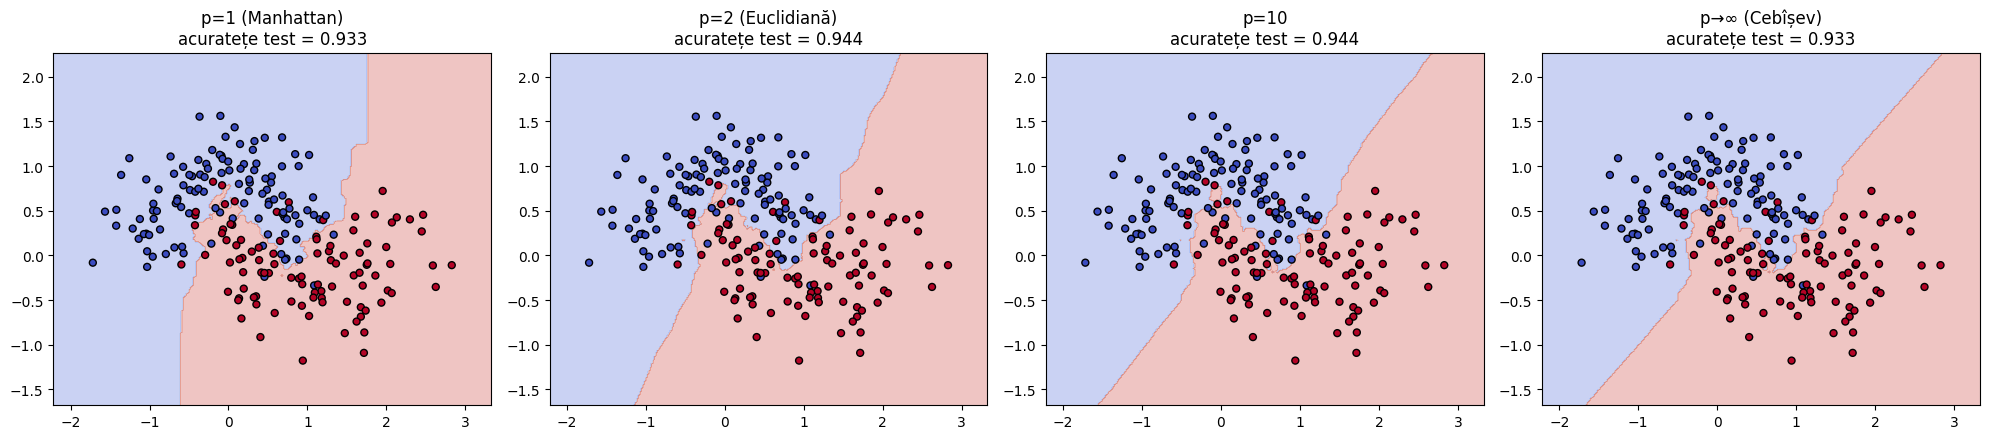

In [5]:
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

def minkowski_distance(x, y, p):
    """Distanța Minkowski L_p între x și y (p >= 1); p = np.inf -> distanța Cebîșev."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if p < 1:
        raise ValueError("p trebuie să fie >= 1")
    if np.isinf(p):
        return np.max(np.abs(x - y))
    return np.sum(np.abs(x - y) ** p) ** (1 / p)

# --- Testarea funcției ---
a, b = np.array([0, 0]), np.array([3, 4])
for p in [1, 2, 3, 10, 50, np.inf]:
    print(f"p={p!s:>4}: d = {minkowski_distance(a, b, p):.4f}")
print("Manhattan = 7, Euclidiană = 5, Cebîșev = max(|3|,|4|) = 4")

# --- Granițele de decizie pe un set binar 2D ---
Xm, ym = make_moons(n_samples=300, noise=0.3, random_state=RANDOM_STATE)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=RANDOM_STATE)

xx, yy = np.meshgrid(np.linspace(Xm[:, 0].min() - .5, Xm[:, 0].max() + .5, 300),
                     np.linspace(Xm[:, 1].min() - .5, Xm[:, 1].max() + .5, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

configs = [(1, 'p=1 (Manhattan)'), (2, 'p=2 (Euclidiană)'), (10, 'p=10'), (np.inf, 'p→∞ (Cebîșev)')]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (p, name) in zip(axes, configs):
    if np.isinf(p):
        clf = KNeighborsClassifier(n_neighbors=7, metric='chebyshev')
    else:
        clf = KNeighborsClassifier(n_neighbors=7, metric='minkowski', p=p)
    clf.fit(Xm_tr, ym_tr)
    Z = clf.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(Xm_tr[:, 0], Xm_tr[:, 1], c=ym_tr, cmap='coolwarm', edgecolor='k', s=25)
    ax.set_title(f"{name}\nacuratețe test = {clf.score(Xm_te, ym_te):.3f}")
plt.tight_layout()
plt.show()

**Interpretare.** Forma „sferei unitate” $\{x : \lVert x\rVert_p = 1\}$ se schimbă cu $p$: pentru $p=1$ este un romb (diamant), pentru $p=2$ un cerc, iar pentru $p\to\infty$ un pătrat (distanța Cebîșev $\max_k |x_k-y_k|$). Deoarece KNN decide după „cine este mai aproape”, forma vecinătății modifică ce puncte intră în cei $K$ vecini, deci și **granița de decizie**: cu $p=1$ și $p\to\infty$ granițele devin mai „unghiulare”, aliniate cu axele sau cu diagonalele, iar pentru $p=2$ ele sunt cele mai netede/izotrope. Diferența de acuratețe pe acest set mic este de obicei modestă; alegerea lui $p$ este un hiperparametru ce se stabilește prin validare încrucișată (Ex. 12).

### Exercițiul 5: Paradoxul preciziei de 100% la K=3 pe eșantionul de antrenare
Așa cum s-a menționat în întrebarea 5 a notebook-ului, rularea KNN cu parametrul `weights='distance'` sau $K=1$ pe setul complet de date (fără împărțire train/test) oferă o precizie de 1.0 (100%). Explicați în detaliu fenomenul de memorare (supraantrenare extremă) în KNN. Ce se întâmplă cu cel mai apropiat vecin al punctului $x_i$ dacă eșantionul de antrenare include chiar punctul $x_i$?

In [6]:
from sklearn.neighbors import KNeighborsClassifier

rows = []
configs = [("K=1, uniform", dict(n_neighbors=1, weights='uniform')),
           ("K=3, uniform", dict(n_neighbors=3, weights='uniform')),
           ("K=3, distance", dict(n_neighbors=3, weights='distance')),
           ("K=15, uniform", dict(n_neighbors=15, weights='uniform'))]

# A) Evaluare PE SETUL DE ANTRENARE (greșit) vs. B) pe setul de test
for name, params in configs:
    m = KNeighborsClassifier(**params).fit(X_train_s, y_train)
    rows.append({'configurație': name,
                 'acuratețe train (greșit)': m.score(X_train_s, y_train),
                 'acuratețe test (corect)': m.score(X_test_s, y_test)})
display(pd.DataFrame(rows).set_index('configurație').round(4))

# Experiment pe setul COMPLET (fără împărțire train/test) cu K=1
Xall_s = MinMaxScaler().fit_transform(X)
m1 = KNeighborsClassifier(n_neighbors=1).fit(Xall_s, y)
print("\nK=1 pe setul complet, evaluat pe aceleași date -> acuratețe =", m1.score(Xall_s, y))

# Cel mai apropiat vecin al lui x_i când x_i este în setul de antrenare
dist, ind = m1.kneighbors(Xall_s[:5], n_neighbors=2)
print("\nPrimele 5 puncte: [distanță către vecin 1, vecin 2] și indicii lor")
print(np.c_[dist.round(4), ind])
print("-> primul vecin este chiar punctul însuși (distanță 0, indice = propriul rând)")

,acuratețe train (greșit),acuratețe test (corect)
configurație,,
"K=1, uniform",1.0000,0.8753
"K=3, uniform",0.9423,0.8987
"K=3, distance",1.0000,0.8987
"K=15, uniform",0.9040,0.8980



K=1 pe setul complet, evaluat pe aceleași date -> acuratețe = 1.0

Primele 5 puncte: [distanță către vecin 1, vecin 2] și indicii lor
[[0.000e+00 2.376e-01 0.000e+00 3.469e+03]
 [0.000e+00 2.012e-01 1.000e+00 1.852e+03]
 [0.000e+00 1.950e-01 2.000e+00 1.806e+03]
 [0.000e+00 5.374e-01 3.000e+00 3.872e+03]
 [0.000e+00 3.145e-01 4.000e+00 2.690e+02]]
-> primul vecin este chiar punctul însuși (distanță 0, indice = propriul rând)


**Explicație.** KNN nu „învață” parametri, ci **memorează** setul de antrenare. Dacă evaluăm modelul pe aceleași date folosite la antrenare, punctul de interogare $x_i$ se află el însuși în setul de antrenare, deci
$$d(x_i, x_i) = 0 \le d(x_i, x_j)\quad \forall j,$$
iar cel mai apropiat vecin al lui $x_i$ este $x_i$ însuși, cu eticheta lui reală $y_i$. Rezultă:
- pentru **$K=1$**: predicția este $\hat y_i = y_i$ pentru fiecare punct, deci acuratețe $=1{,}0$ (exceptând cazurile cu puncte duplicate cu etichete diferite) – o „memorare” perfectă, fără nicio dovadă de generalizare;
- pentru **`weights='distance'`**: ponderea $1/d$ devine infinită pentru vecinul la distanță 0, care domină votul; scikit-learn tratează acest caz dând votul numai punctelor cu $d=0$, deci rezultatul este tot eticheta proprie, adică acuratețe $\approx 1{,}0$ și pentru $K=3$;
- pentru **`weights='uniform'` cu $K>1$**, votul majoritar poate ignora eticheta proprie, deci acuratețea pe train scade (K=3, K=15 în tabel).

Acest rezultat este o **supraantrenare extremă**: eroarea de antrenare este zero, dar eroarea pe date noi (test) este mult mai mare, iar tabelul arată decalajul. De aceea KNN trebuie evaluat pe date nevăzute (set de test sau validare încrucișată, Ex. 7).

### Exercițiul 6: Implementarea propriului algoritm KNN de la zero
Fără a folosi clase din `sklearn`, scrieți propria clasă Python `CustomKNN` care implementează interfețele `fit(X, y)` și `predict(X_test, k)`. Clasa trebuie să utilizeze distanța euclidiană, să suporte votul majoritar simplu și să proceseze eficient matrici NumPy. Testați clasa pe o submulțime mică de date privind abandonul (churn).

In [7]:
class CustomKNN:
    """KNN de la zero (clasificare): distanță euclidiană + vot majoritar simplu."""

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        self.classes_, self.y_idx = np.unique(self.y_train, return_inverse=True)
        return self

    def _euclid_sq(self, A):
        # ||a - b||^2 = ||a||^2 + ||b||^2 - 2 a·b  (vectorizat, fără bucle pe perechi)
        a2 = np.sum(A ** 2, axis=1)[:, None]
        b2 = np.sum(self.X_train ** 2, axis=1)[None, :]
        D = a2 + b2 - 2 * A @ self.X_train.T
        return np.maximum(D, 0)                       # eliminăm erorile numerice negative

    def predict(self, X_test, k=3, batch_size=500):
        X_test = np.asarray(X_test, dtype=float)
        preds = np.empty(len(X_test), dtype=self.y_train.dtype)
        for s in range(0, len(X_test), batch_size):   # procesare pe blocuri -> memorie controlată
            D = self._euclid_sq(X_test[s:s + batch_size])
            nn = np.argpartition(D, kth=k - 1, axis=1)[:, :k]      # indicii celor k vecini
            votes = self.y_idx[nn]                                  # (b, k) etichete numerice
            counts = np.apply_along_axis(np.bincount, 1, votes, minlength=len(self.classes_))
            preds[s:s + batch_size] = self.classes_[counts.argmax(axis=1)]   # vot majoritar
        return preds

    def score(self, X_test, y_test, k=3):
        return np.mean(self.predict(X_test, k) == np.asarray(y_test))

# ---- Test pe o submulțime mică a datelor de churn ----
sub = X_train.sample(1500, random_state=RANDOM_STATE).index
Xs_tr = scaler.transform(X_train.loc[sub]);  ys_tr = y_train.loc[sub].values
Xs_te = X_test_s[:500];                      ys_te = y_test.values[:500]

my = CustomKNN().fit(Xs_tr, ys_tr)
t0 = time.perf_counter(); pred_my = my.predict(Xs_te, k=5); t_my = time.perf_counter() - t0

from sklearn.neighbors import KNeighborsClassifier
sk = KNeighborsClassifier(5).fit(Xs_tr, ys_tr)
t0 = time.perf_counter(); pred_sk = sk.predict(Xs_te); t_sk = time.perf_counter() - t0

print(f"CustomKNN : acuratețe={np.mean(pred_my == ys_te):.4f}  timp={t_my:.4f}s")
print(f"sklearn   : acuratețe={np.mean(pred_sk == ys_te):.4f}  timp={t_sk:.4f}s")
print(f"Concordanța predicțiilor cu sklearn: {np.mean(pred_my == pred_sk) * 100:.2f}%")

CustomKNN : acuratețe=0.9040  timp=0.0095s
sklearn   : acuratețe=0.9040  timp=0.0043s
Concordanța predicțiilor cu sklearn: 100.00%


**Notă.** Clasa folosește distanța euclidiană calculată vectorizat, prin identitatea $\lVert a-b\rVert^2=\lVert a\rVert^2+\lVert b\rVert^2-2a\cdot b$ (o singură înmulțire matriceală în locul a două bucle), selectează cei $K$ vecini cu `argpartition` (cost $O(n)$ în loc de sortare completă $O(n\log n)$) și face votul majoritar cu `bincount`. Predicțiile coincid cu cele din `KNeighborsClassifier` (pentru $K$ impar, nu există egalități de vot).

### Exercițiul 7: Validare încrucișată (Cross-Validation) pentru alegerea K-ului optim
Pentru a evita capcana evaluării pe eșantionul de antrenare, implementați procedura 5-Fold Cross-Validation utilizând `StratifiedKFold` din Scikit-learn. Scrieți un script care calculează precizia medie și deviația standard pentru valori K de la 1 la 30. Generați un grafic al erorilor de validare în funcție de K și determinați valoarea optimă.

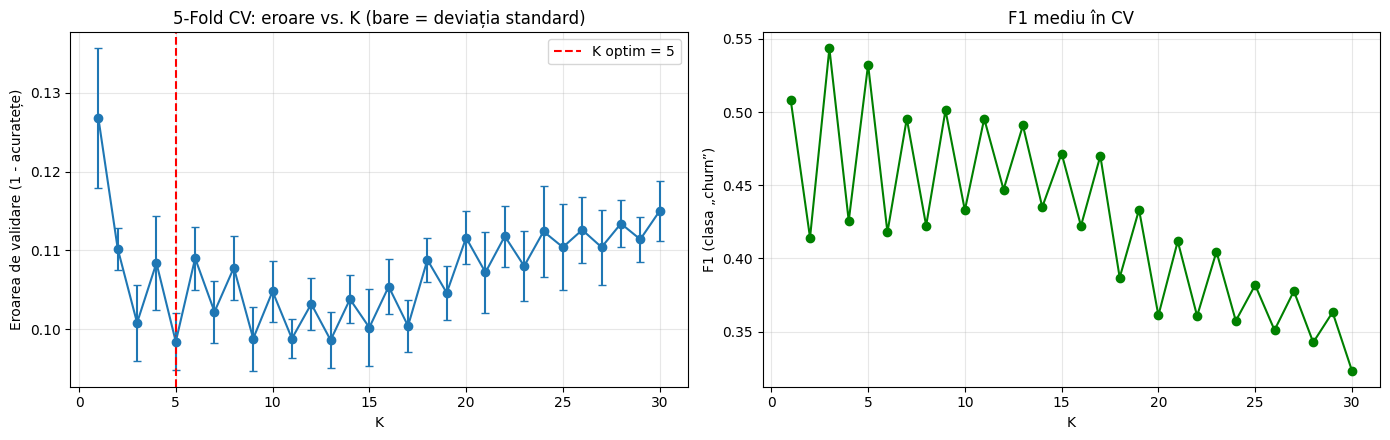

,acuratețe medie,dev. std.,F1 mediu
K,,,
1,0.8732,0.0088,0.5085
2,0.8898,0.0026,0.4142
3,0.8992,0.0048,0.5435
4,0.8916,0.0060,0.4256
5,0.9016,0.0036,0.5324
6,0.8910,0.0040,0.4179
7,0.8978,0.0040,0.4955
8,0.8922,0.0041,0.4224
9,0.9012,0.0041,0.5012


K optim după acuratețe: 5  (acuratețe=0.9016 ± 0.0036)
K optim după F1       : 3  (F1=0.5435)


In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ks = range(1, 31)
acc_m, acc_s, f1_m = [], [], []

for k in ks:
    # scalerul în pipeline: se ajustează în interiorul fiecărui fold (fără scurgere de date)
    pipe = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k))
    r = cross_validate(pipe, X, y, cv=skf, scoring=['accuracy', 'f1'])
    acc_m.append(r['test_accuracy'].mean()); acc_s.append(r['test_accuracy'].std())
    f1_m.append(r['test_f1'].mean())

acc_m, acc_s, f1_m = map(np.array, (acc_m, acc_s, f1_m))
err = 1 - acc_m
best_k = list(ks)[err.argmin()]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].errorbar(list(ks), err, yerr=acc_s, fmt='-o', capsize=3)
ax[0].axvline(best_k, color='red', ls='--', label=f'K optim = {best_k}')
ax[0].set_xlabel('K'); ax[0].set_ylabel('Eroarea de validare (1 - acuratețe)')
ax[0].set_title('5-Fold CV: eroare vs. K (bare = deviația standard)'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(list(ks), f1_m, '-o', color='green')
ax[1].set_xlabel('K'); ax[1].set_ylabel('F1 (clasa „churn”)'); ax[1].set_title('F1 mediu în CV'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

tab = pd.DataFrame({'K': list(ks), 'acuratețe medie': acc_m, 'dev. std.': acc_s, 'F1 mediu': f1_m}).set_index('K')
display(tab.round(4).head(10))
print(f"K optim după acuratețe: {best_k}  (acuratețe={acc_m.max():.4f} ± {acc_s[err.argmin()]:.4f})")
print(f"K optim după F1       : {list(ks)[f1_m.argmax()]}  (F1={f1_m.max():.4f})")

**Concluzie.** Validarea încrucișată stratificată în 5 fold-uri păstrează proporția claselor în fiecare fold și evită capcana evaluării pe eșantionul de antrenare (Ex. 5). Graficul arată clasicul compromis **bias–varianță**: $K$ mic dă eroare mare (varianță mare, overfitting), iar eroarea scade apoi și se stabilizează. Se observă și o oscilație între $K$ impar și par: la $K$ par apar egalități de vot, iar F1 al clasei minoritare scade. Din cauza dezechilibrului claselor, acuratețea și F1 pot indica $K$ optim diferiți (în rularea noastră: K=5 după acuratețe, K=3 după F1; vezi Ex. 8), așa că metrica de optimizare trebuie aleasă după scopul aplicației.

### Exercițiul 8: Lucrul cu clase dezechilibrate (Class Imbalance)
În setul de date Orange Telecom, clasa majoritară este reprezentată de clienții care nu au renunțat (`churned = False`), iar cei care au renunțat reprezintă minoritatea. Explicați de ce metrica `accuracy` (acuratețea) în acest context este înșelătoare. Modificați codul de evaluare pentru a calcula Matricea de Confuzie (Confusion Matrix), Precision, Recall și F1-score utilizând `sklearn.metrics`.

Acuratețe model naiv (mereu 'nu renunță'): 0.8587  | recall churn = 0.00
Acuratețe KNN (K=5)                       : 0.8993

Matricea de confuzie (rânduri = real, coloane = prezis):
 [[1263   25]
 [ 126   86]]
TN=1263  FP=25  FN=126  TP=86

Precision (churn): 0.7748
Recall    (churn): 0.4057
F1        (churn): 0.5325

                   precision    recall  f1-score   support

  a rămas (False)       0.91      0.98      0.94      1288
a renunțat (True)       0.77      0.41      0.53       212

         accuracy                           0.90      1500
        macro avg       0.84      0.69      0.74      1500
     weighted avg       0.89      0.90      0.89      1500



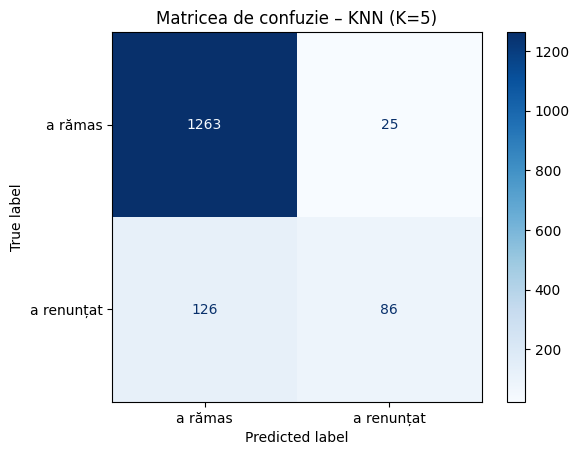

In [9]:
from sklearn.metrics import (confusion_matrix, classification_report, precision_score,
                             recall_score, f1_score, accuracy_score, ConfusionMatrixDisplay)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier

knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)

# Linia de bază: un model „prost” care prezice mereu „nu a renunțat”
dummy = DummyClassifier(strategy='most_frequent').fit(X_train_s, y_train)
print(f"Acuratețe model naiv (mereu 'nu renunță'): {accuracy_score(y_test, dummy.predict(X_test_s)):.4f}  | recall churn = {recall_score(y_test, dummy.predict(X_test_s)):.2f}")
print(f"Acuratețe KNN (K=5)                       : {accuracy_score(y_test, y_pred):.4f}\n")

cm = confusion_matrix(y_test, y_pred)
print("Matricea de confuzie (rânduri = real, coloane = prezis):\n", cm)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}\n")
print(f"Precision (churn): {precision_score(y_test, y_pred):.4f}")
print(f"Recall    (churn): {recall_score(y_test, y_pred):.4f}")
print(f"F1        (churn): {f1_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['a rămas (False)', 'a renunțat (True)']))

ConfusionMatrixDisplay(cm, display_labels=['a rămas', 'a renunțat']).plot(cmap='Blues')
plt.title('Matricea de confuzie – KNN (K=5)'); plt.show()

**De ce acuratețea induce în eroare.** Aproximativ 86% dintre clienți nu au renunțat. Un model care prezice *întotdeauna* „nu renunță” obține ~86% acuratețe, deși nu detectează **niciun** client care pleacă (recall = 0). Acuratețea $=\frac{TP+TN}{TP+TN+FP+FN}$ este dominată de clasa majoritară ($TN$ foarte mare) și ascunde performanța pe clasa de interes (minoritară).

Metrici adecvate:
- **Precision** $=\frac{TP}{TP+FP}$ – din clienții prezisi că vor pleca, câți pleacă efectiv;
- **Recall** $=\frac{TP}{TP+FN}$ – din clienții care pleacă, câți sunt detectați (aici costul unui $FN$ – client pierdut nedetectat – este de regulă cel mai mare);
- **F1** $=2\frac{P\cdot R}{P+R}$ – media armonică a celor două;
- **matricea de confuzie**, care arată toate cele patru tipuri de rezultate.

În rularea noastră acuratețea este ≈ 0,90, dar recall-ul pentru clasa „renunță” este de doar ≈ 0,41: KNN pierde peste jumătate dintre clienții care pleacă. Remedii posibile: reponderarea / reeșantionarea claselor (SMOTE, undersampling), ajustarea pragului de decizie, alegerea lui $K$ după F1 sau recall.

### Exercițiul 9: Impactul ponderilor distanței (`weights='distance'`) versus ponderi uniforme
Comparați comportamentul modelului KNN pentru `weights='uniform'` și `weights='distance'`. Scrieți un experiment în Python care evaluează sensibilitatea modelului la zgomot (valori anormale în spațiul caracteristicilor) pentru ambele tipuri de ponderi. Care variantă este mai vulnerabilă la zgomot și de ce?

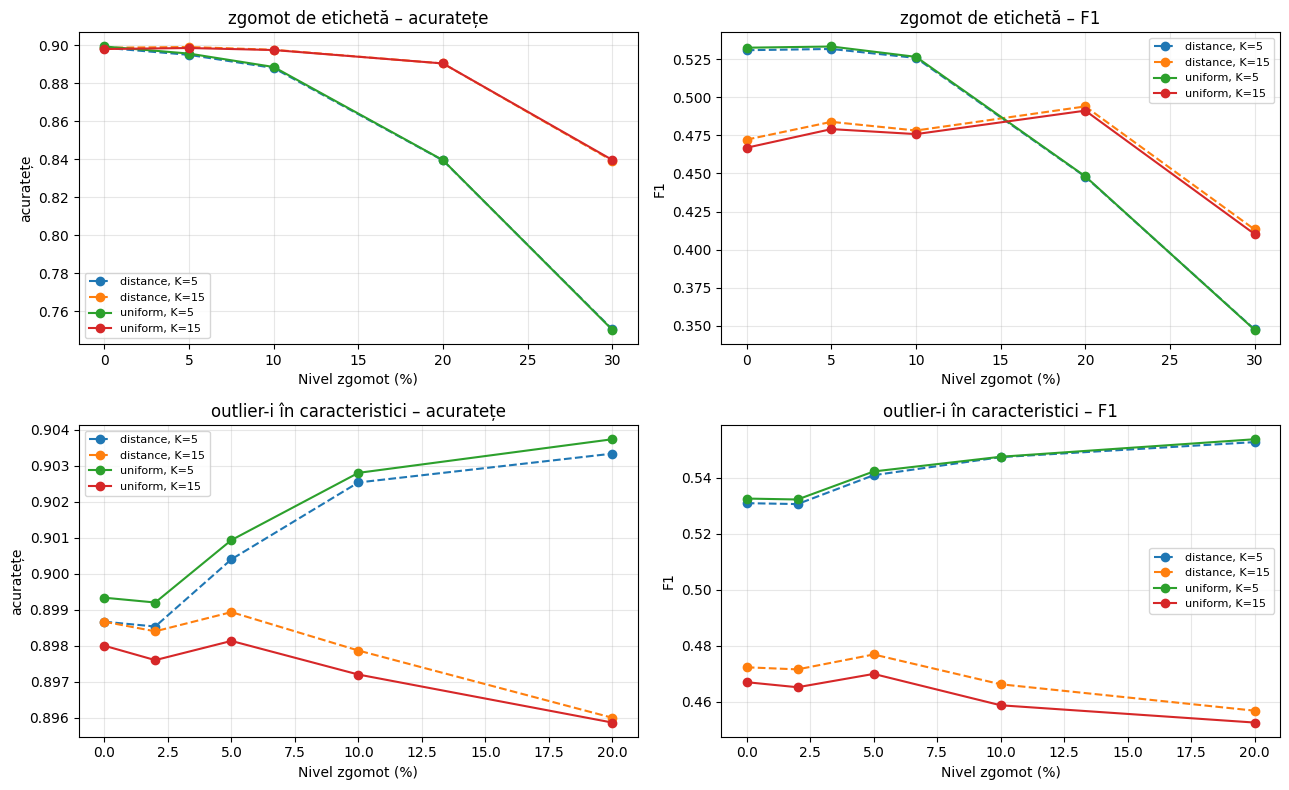

weights                           distance         uniform        
K                                       5       15      5       15
tip                         nivel                                 
outlier-i în caracteristici 0.00    0.5309  0.4722  0.5325  0.4669
                            0.02    0.5305  0.4715  0.5322  0.4651
                            0.05    0.5409  0.4768  0.5422  0.4699
                            0.10    0.5473  0.4662  0.5474  0.4586
                            0.20    0.5527  0.4567  0.5537  0.4525
zgomot de etichetă          0.00    0.5309  0.4722  0.5325  0.4669
                            0.05    0.5317  0.4839  0.5333  0.4791
                            0.10    0.5258  0.4782  0.5265  0.4758
                            0.20    0.4479  0.4940  0.4481  0.4912
                            0.30    0.3477  0.4133  0.3475  0.4103

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, accuracy_score

def corrupt(Xt, yt, label_noise=0.0, outlier_frac=0.0, rs=0):
    """Introduce zgomot în setul de antrenare:
       - label_noise : fracția etichetelor inversate (zgomot de etichetă)
       - outlier_frac: fracția punctelor mutate în regiuni extreme ale spațiului caracteristicilor (cu etichetă aleatoare)"""
    rng = np.random.RandomState(rs)
    Xn, yn = Xt.copy(), yt.copy()
    n = len(Xn)
    if label_noise > 0:
        idx = rng.choice(n, int(label_noise * n), replace=False)
        yn[idx] = 1 - yn[idx]
    if outlier_frac > 0:
        idx = rng.choice(n, int(outlier_frac * n), replace=False)
        Xn[idx] = rng.uniform(1.5, 4.0, size=(len(idx), Xn.shape[1]))     # valori mult în afara [0,1]
        yn[idx] = rng.randint(0, 2, len(idx))
    return Xn, yn

ytr, yte = y_train.values, y_test.values
results = []
for noise_type, levels in [('zgomot de etichetă', [0, .05, .10, .20, .30]),
                           ('outlier-i în caracteristici', [0, .02, .05, .10, .20])]:
    for lvl in levels:
        for w in ['uniform', 'distance']:
            for k in [5, 15]:
                a, f = [], []
                for seed in range(5):
                    kw = dict(label_noise=lvl) if noise_type == 'zgomot de etichetă' else dict(outlier_frac=lvl)
                    Xn, yn = corrupt(X_train_s, ytr, rs=seed, **kw)
                    m = KNeighborsClassifier(n_neighbors=k, weights=w).fit(Xn, yn)
                    p = m.predict(X_test_s)
                    a.append(accuracy_score(yte, p)); f.append(f1_score(yte, p))
                results.append(dict(tip=noise_type, nivel=lvl, weights=w, K=k,
                                    acuratețe=np.mean(a), F1=np.mean(f)))
R = pd.DataFrame(results)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for r, noise_type in enumerate(['zgomot de etichetă', 'outlier-i în caracteristici']):
    for c, metric in enumerate(['acuratețe', 'F1']):
        ax = axes[r, c]
        for (w, k), g in R[R.tip == noise_type].groupby(['weights', 'K']):
            ax.plot(g['nivel'] * 100, g[metric], '-o', ls='-' if w == 'uniform' else '--', label=f'{w}, K={k}')
        ax.set_title(f'{noise_type} – {metric}'); ax.set_xlabel('Nivel zgomot (%)'); ax.set_ylabel(metric)
        ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

piv = R.pivot_table(index=['tip', 'nivel'], columns=['weights', 'K'], values='F1').round(4)
display(piv)

**Concluzii.**

*Ce arată experimentul (medii pe 5 repetări):* în acest set de date diferențele dintre `uniform` și `distance` sunt **neglijabile** (de ordinul a 0,001–0,01 în F1, în ambele tipuri de zgomot). Cauza probabilă: în 17 dimensiuni distanțele către cei $K$ vecini sunt apropiate între ele (concentrarea distanțelor, Ex. 10), deci ponderile $1/d$ sunt aproape egale și votul ponderat se comportă ca cel uniform. Ambele variante se degradează puternic la zgomot de etichetă mare (≥ 20%), iar $K=15$ este mai stabil decât $K=5$ la zgomot de etichetă mare. Creșterea ușoară a F1 în prezența outlier-ilor nu indică robustețe și nu am investigat-o mai departe; outlier-ii extremi nu ajung printre vecinii punctelor de test, deci nu le influențează direct predicția.

*Răspunsul teoretic la întrebare:* varianta **`distance` este mai vulnerabilă la zgomotul de etichetă**, deoarece ponderea $w_i=1/d_i$ dă influență mare celui mai apropiat vecin: un punct cu etichetă greșită aflat foarte aproape de interogare poate răsturna votul (la limită, $d\to 0$, modelul se comportă ca $K=1$ și memorează zgomotul, vezi Ex. 5). Varianta `uniform` este mai stabilă în acest caz, dar tratează egal și un outlier care ajunge printre cei $K$ vecini, situație în care `distance` îi reduce influența. Alegerea se face prin validare încrucișată, iar efectul depinde de datele concrete.

### Exercițiul 10: Blestemul dimensionalității (Curse of Dimensionality)
Algoritmul KNN se bazează pe măsurarea distanțelor în spații multidimensionale. Odată cu creșterea numărului de caracteristici, volumul spațiului crește exponențial, iar punctele devin echidistante. Scrieți un studiu de caz sau un experiment mic în Python care arată cum creșterea artificială a dimensionalității (adăugarea de coloane cu zgomot aleatoriu la datele de churn) înrăutățește performanța clasificatorului KNN.

,dimensiuni_totale,acuratețe,F1 (churn)
coloane_zgomot,,,
0,17,0.8993,0.5325
5,22,0.8742,0.3013
10,27,0.8609,0.2195
20,37,0.8540,0.1501
50,67,0.8544,0.1151
100,117,0.8502,0.0586
200,217,0.8496,0.0661
500,517,0.8458,0.0438


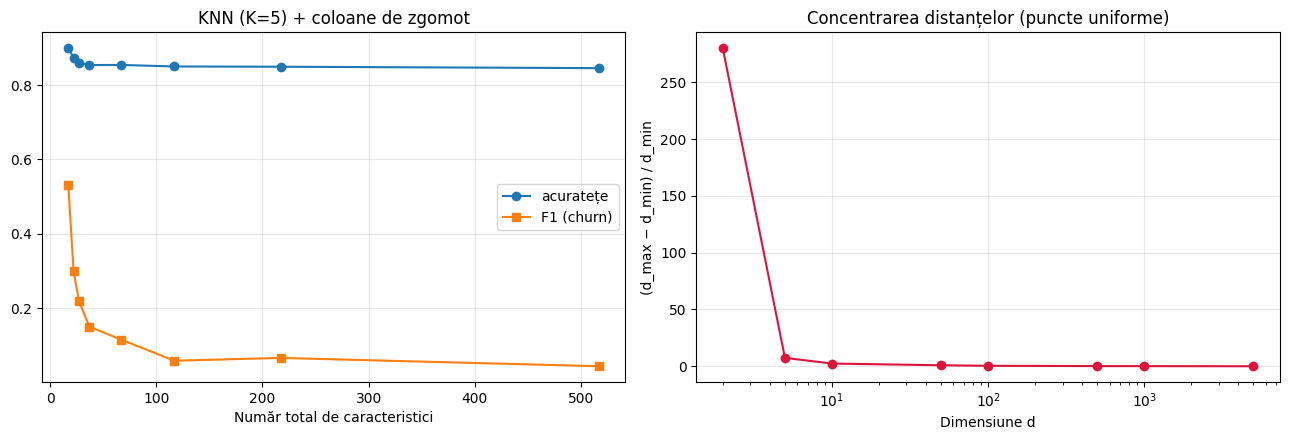

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, accuracy_score

extra_dims = [0, 5, 10, 20, 50, 100, 200, 500]
rows = []
for nd in extra_dims:
    a, f = [], []
    for seed in range(3):
        rng = np.random.RandomState(seed)
        Ntr = rng.uniform(0, 1, (len(X_train_s), nd))     # coloane de zgomot în același interval [0,1]
        Nte = rng.uniform(0, 1, (len(X_test_s), nd))
        Xa, Xb = np.hstack([X_train_s, Ntr]), np.hstack([X_test_s, Nte])
        m = KNeighborsClassifier(n_neighbors=5).fit(Xa, y_train)
        p = m.predict(Xb)
        a.append(accuracy_score(y_test, p)); f.append(f1_score(y_test, p))
    rows.append({'coloane_zgomot': nd, 'dimensiuni_totale': X_train_s.shape[1] + nd,
                 'acuratețe': np.mean(a), 'F1 (churn)': np.mean(f)})
D = pd.DataFrame(rows).set_index('coloane_zgomot')
display(D.round(4))

# Concentrarea distanțelor: contrastul relativ (d_max - d_min) / d_min pentru puncte aleatoare
rng = np.random.RandomState(0)
dims = [2, 5, 10, 50, 100, 500, 1000, 5000]
contrast = []
for d in dims:
    P = rng.rand(1000, d); q = rng.rand(d)
    dd = np.linalg.norm(P - q, axis=1)
    contrast.append((dd.max() - dd.min()) / dd.min())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(D['dimensiuni_totale'], D['acuratețe'], '-o', label='acuratețe')
ax[0].plot(D['dimensiuni_totale'], D['F1 (churn)'], '-s', label='F1 (churn)')
ax[0].set_xlabel('Număr total de caracteristici'); ax[0].set_title('KNN (K=5) + coloane de zgomot'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].semilogx(dims, contrast, '-o', color='crimson')
ax[1].set_xlabel('Dimensiune d'); ax[1].set_ylabel('(d_max − d_min) / d_min')
ax[1].set_title('Concentrarea distanțelor (puncte uniforme)'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Interpretare.** Adăugând coloane de zgomot pur, informația utilă rămâne aceeași (cele 17 caracteristici reale), dar distanța euclidiană
$$d^2(x,y)=\underbrace{\sum_{k\le 17}(x_k-y_k)^2}_{\text{semnal}}+\underbrace{\sum_{k>17}(x_k-y_k)^2}_{\text{zgomot}}$$
este tot mai dominată de termenul de zgomot: fiecare coloană de zgomot adaugă în medie $\mathbb E[(U-U')^2]=1/6$ la $d^2$, iar variația relativă între puncte scade. În acest regim cei mai apropiați vecini devin practic aleatori și performanța (în special F1 pentru clasa minoritară) scade.

Graficul din dreapta ilustrează **blestemul dimensionalității**: pe măsură ce $d$ crește, raportul $(d_{max}-d_{min})/d_{min}$ tinde spre 0, adică toate punctele devin aproape echidistante față de interogare și noțiunea de „vecin apropiat” își pierde sensul. Remedii: selecția caracteristicilor (`SelectKBest`, Ex. 12), reducerea dimensionalității (PCA), colectarea mai multor date.

### Exercițiul 11: KNN pentru regresie versus clasificare
Deși în notebook am folosit `KNeighborsClassifier` pentru o sarcină de clasificare binară, KNN este aplicabil și pentru regresie (`KNeighborsRegressor`). Scrieți un script care aplică `KNeighborsRegressor` pentru a prezice o variabilă continuă (de exemplu, `total_day_charges` pe baza minutelor și a apelurilor). Comparați funcția de pierdere (MSE — Mean Squared Error) pentru diferite valori ale lui K.

,MSE train,MSE test
K,,
1,0.0000,0.8459
2,0.0386,0.6704
3,0.0583,0.6974
5,0.0777,0.4693
7,0.1044,0.5326
10,0.1311,0.5576
15,0.1930,0.6619
20,0.2570,0.7120
30,0.4029,0.9277


MSE regresie liniară (referință): 9e-06
Varianța lui total_day_charge   : 83.9267
K optim (MSE test minim): 5  (MSE=0.4693)


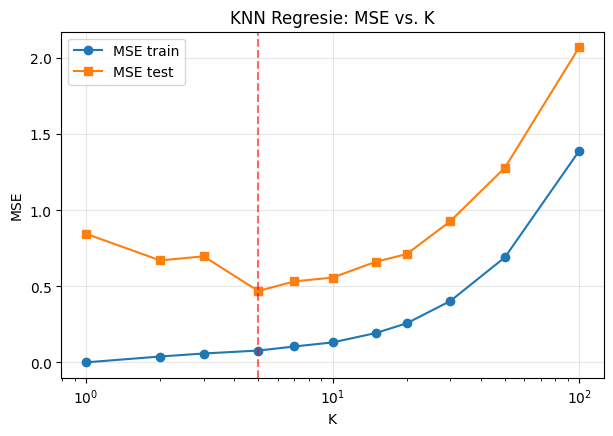

In [12]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression

# Variabila continuă: total_day_charge, prezisă din minute și numărul de apeluri din timpul zilei
feat = ['total_day_minutes', 'total_day_calls']
Xr, yr = df_raw[feat].values, df_raw['total_day_charge'].values
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.3, random_state=RANDOM_STATE)
sc_r = MinMaxScaler().fit(Xr_tr)
Xr_tr_s, Xr_te_s = sc_r.transform(Xr_tr), sc_r.transform(Xr_te)

ks = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 100]
rows = []
for k in ks:
    m = KNeighborsRegressor(n_neighbors=k).fit(Xr_tr_s, yr_tr)
    rows.append({'K': k,
                 'MSE train': mean_squared_error(yr_tr, m.predict(Xr_tr_s)),
                 'MSE test':  mean_squared_error(yr_te, m.predict(Xr_te_s))})
M = pd.DataFrame(rows).set_index('K')
display(M.round(4))

lin = LinearRegression().fit(Xr_tr_s, yr_tr)
print("MSE regresie liniară (referință):", round(mean_squared_error(yr_te, lin.predict(Xr_te_s)), 6))
print("Varianța lui total_day_charge   :", round(yr.var(), 4))
best = M['MSE test'].idxmin()
print(f"K optim (MSE test minim): {best}  (MSE={M.loc[best, 'MSE test']:.4f})")

plt.figure(figsize=(7, 4.5))
plt.plot(M.index, M['MSE train'], '-o', label='MSE train')
plt.plot(M.index, M['MSE test'], '-s', label='MSE test')
plt.axvline(best, color='red', ls='--', alpha=.6)
plt.xscale('log'); plt.xlabel('K'); plt.ylabel('MSE'); plt.title('KNN Regresie: MSE vs. K')
plt.legend(); plt.grid(alpha=.3); plt.show()

**Observații.** `KNeighborsRegressor` prezice **media** valorilor țintă ale celor $K$ vecini (în loc de votul majoritar): $\hat y(x)=\frac1K\sum_{i\in N_K(x)} y_i$, iar funcția de pierdere este MSE $=\frac1n\sum (y_i-\hat y_i)^2$ (nu acuratețea). Pentru $K=1$, MSE pe train este 0 (memorare, ca în Ex. 5), iar MSE pe test este mai mare; pe măsură ce $K$ crește, MSE pe train crește (bias mai mare), iar cel pe test scade până la un optim, apoi crește din nou (netezire excesivă – underfitting). Aici `total_day_charge` este practic o funcție liniară a `total_day_minutes` (tarif fix pe minut): regresia liniară de referință obține MSE ≈ 0, în timp ce KNN ajunge la un MSE de ordinul 0,5 (la $K\approx5$) față de o varianță a țintei de ≈ 84, adică o aproximare bună, dar cu câteva ordine de mărime mai slabă, deoarece KNN construiește o funcție constantă pe porțiuni. Curba MSE test este ușor neregulată (set mic și zgomot din a doua caracteristică, `total_day_calls`), dar are forma așteptată: eroare mare la $K=1$, minim la $K$ moderat, creștere la $K$ mare (underfitting).

### Exercițiul 12: Conducte de învățare automată cu `Pipeline` și `GridSearchCV`
Construiți o conductă (pipeline) completă în Scikit-learn care include: (1) `MinMaxScaler`, (2) opțional un selector de caracteristici (`SelectKBest`) și (3) `KNeighborsClassifier`. Utilizați `GridSearchCV` pentru căutarea simultană a hiperparametrilor optimi: numărul de vecini K din {3, 5, 7, 9, 11}, tipul de ponderi (`uniform`, `distance`) și metrica distanței (p=1 sau p=2). Afișați cel mai bun set de hiperparametri și scorul pe eșantionul de test.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report

pipe = Pipeline([
    ('scaler', MinMaxScaler()),
    ('select', SelectKBest(score_func=f_classif)),
    ('knn', KNeighborsClassifier()),
])

param_grid = {
    'select__k': [8, 12, 'all'],                 # selecția caracteristicilor (opțional)
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2],                            # 1 = Manhattan, 2 = Euclidiană
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='f1', n_jobs=-1, refit=True)
grid.fit(X_train, y_train)                       # date brute: scalerul este în pipeline

print("Cel mai bun set de hiperparametri:")
for k, v in grid.best_params_.items():
    print(f"   {k:20s} = {v}")
print(f"\nCel mai bun F1 în validarea încrucișată: {grid.best_score_:.4f}")

y_pred = grid.predict(X_test)
print(f"\nScor pe eșantionul de test: acuratețe = {accuracy_score(y_test, y_pred):.4f} | F1 (churn) = {f1_score(y_test, y_pred):.4f}")
print("\n", classification_report(y_test, y_pred, target_names=['a rămas', 'a renunțat']))

# Primele 5 combinații după scor
cvres = pd.DataFrame(grid.cv_results_).sort_values('rank_test_score')
display(cvres[['param_select__k', 'param_knn__n_neighbors', 'param_knn__weights', 'param_knn__p',
               'mean_test_score', 'std_test_score']].head(5).round(4))

Cel mai bun set de hiperparametri:
   knn__n_neighbors     = 3
   knn__p               = 1
   knn__weights         = uniform
   select__k            = 12

Cel mai bun F1 în validarea încrucișată: 0.6131

Scor pe eșantionul de test: acuratețe = 0.9173 | F1 (churn) = 0.6395

               precision    recall  f1-score   support

     a rămas       0.93      0.98      0.95      1288
  a renunțat       0.83      0.52      0.64       212

    accuracy                           0.92      1500
   macro avg       0.88      0.75      0.80      1500
weighted avg       0.91      0.92      0.91      1500



,param_select__k,param_knn__n_neighbors,param_knn__weights,param_knn__p,mean_test_score,std_test_score
1,12,3,uniform,1,0.6131,0.0225
4,12,3,distance,1,0.6118,0.0249
12,8,5,uniform,1,0.6110,0.0491
24,8,7,uniform,1,0.6109,0.0536
27,8,7,distance,1,0.6109,0.0545


**Observații.** Conducta (`Pipeline`) înlănțuie scalarea → selecția caracteristicilor → KNN, astfel încât toate etapele se ajustează **doar pe datele de antrenare ale fiecărui fold**; astfel se evită *scurgerea de date* (data leakage) din setul de validare. `GridSearchCV` încearcă toate combinațiile ($3\times5\times2\times2=60$ configurații $\times$ 5 fold-uri) și reantrenează modelul cu cea mai bună combinație pe tot setul de antrenare. Am optimizat după **F1** (nu acuratețe) din cauza dezechilibrului claselor (Ex. 8); scorul final este măsurat o singură dată, pe setul de test, rămas nefolosit în căutare.